In [ ]:
#Cell 1: Load
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

df = pd.read_csv("../data/raw/PJME_hourly.csv", parse_dates=["Datetime"])
df = df.sort_values("Datetime").set_index("Datetime")
df.columns = ["load_mw"]

print(df.shape)
print(df.index.min(), "->", df.index.max())
print(df.describe())

(145366, 1)
2002-01-01 01:00:00 -> 2018-08-03 00:00:00
             load_mw
count  145366.000000
mean    32080.222831
std      6464.012166
min     14544.000000
25%     27573.000000
50%     31421.000000
75%     35650.000000
max     62009.000000


In [ ]:
#Cell 2: Data quality checks
python
print("Missing values:", df["load_mw"].isna().sum())
print("Duplicate timestamps:", df.index.duplicated().sum())

full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Missing hours:", len(full_range.difference(df.index)))

Missing values: 0
Duplicate timestamps: 4
Missing hours: 30


In [ ]:
#Cell 3: Clean
# Duplicates come from daylight saving changes, so average them
df = df.groupby(df.index).mean()

# Reindex to a complete hourly range and interpolate the gaps
df = df.reindex(full_range)
df.index.name = "Datetime"
df["load_mw"] = df["load_mw"].interpolate(method="time")

print("Rows after cleaning:", len(df))
print("Missing values:", df["load_mw"].isna().sum())

Rows after cleaning: 145392
Missing values: 0


In [ ]:
#Cell 4: Calendar features
df["hour"] = df.index.hour
df["dayofweek"] = df.index.dayofweek
df["month"] = df.index.month
df["year"] = df.index.year
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

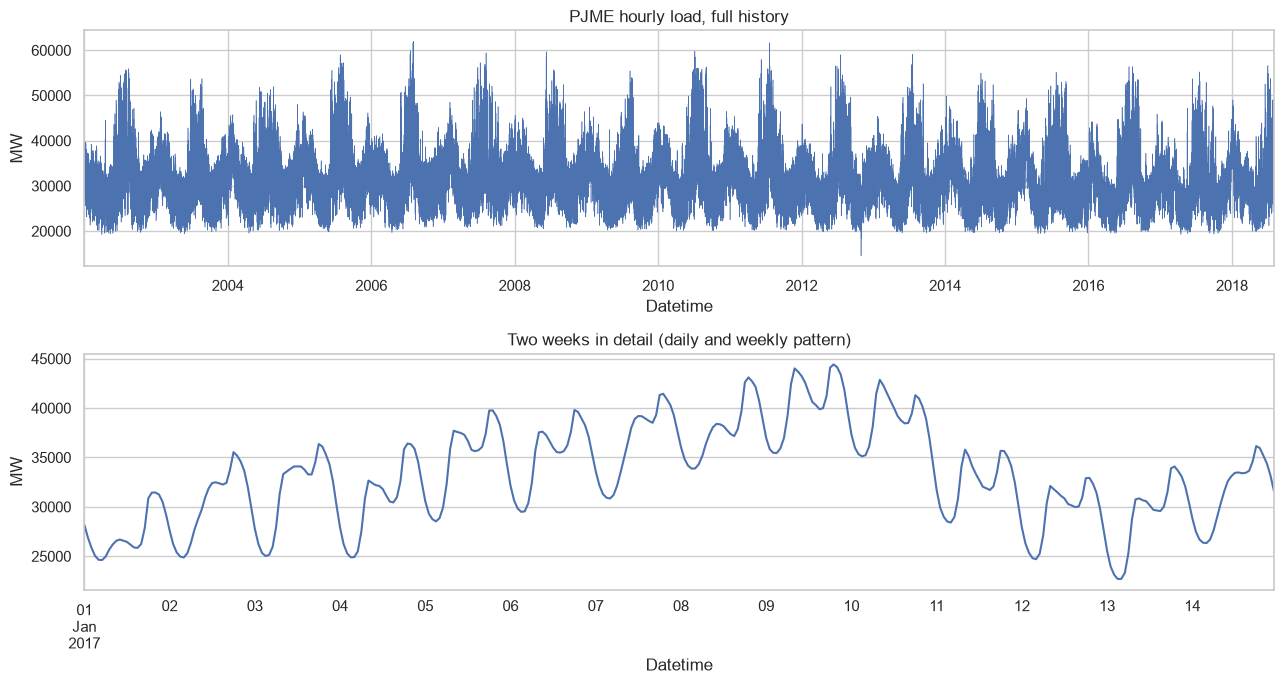

In [ ]:
#Cell 5: Overall series and a zoomed window
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
df["load_mw"].plot(ax=ax[0], lw=0.4)
ax[0].set_title("PJME hourly load, full history")
ax[0].set_ylabel("MW")

df.loc["2017-01-01":"2017-01-14", "load_mw"].plot(ax=ax[1])
ax[1].set_title("Two weeks in detail (daily and weekly pattern)")
ax[1].set_ylabel("MW")

plt.tight_layout()
plt.savefig("../reports/figures/01_load_overview.png", dpi=150)
plt.show()

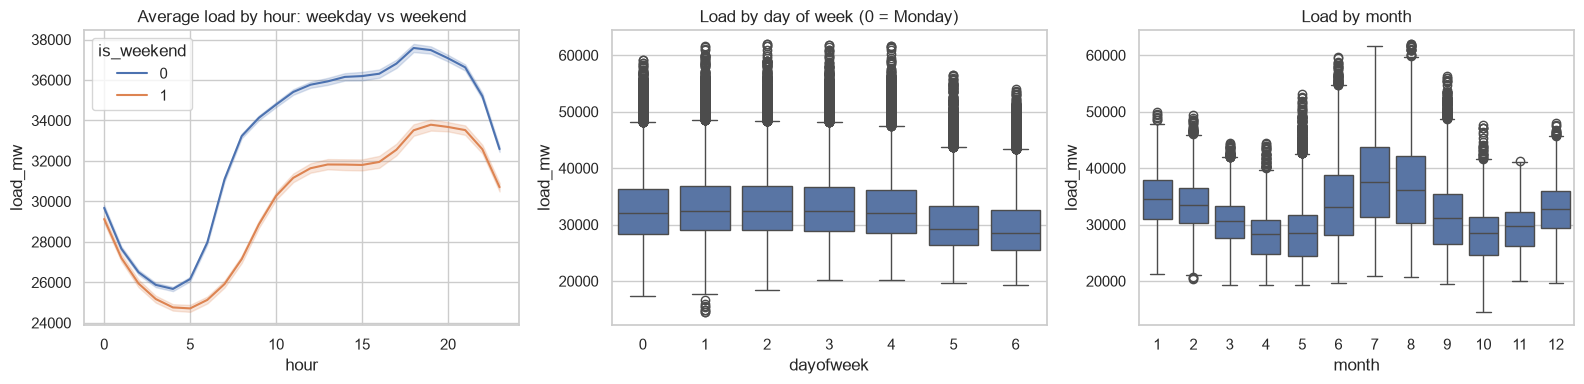

In [ ]:
#Cell 6: Seasonality patterns
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.lineplot(data=df, x="hour", y="load_mw", hue="is_weekend", ax=ax[0])
ax[0].set_title("Average load by hour: weekday vs weekend")

sns.boxplot(data=df, x="dayofweek", y="load_mw", ax=ax[1])
ax[1].set_title("Load by day of week (0 = Monday)")

sns.boxplot(data=df, x="month", y="load_mw", ax=ax[2])
ax[2].set_title("Load by month")

plt.tight_layout()
plt.savefig("../reports/figures/02_seasonality.png", dpi=150)
plt.show()

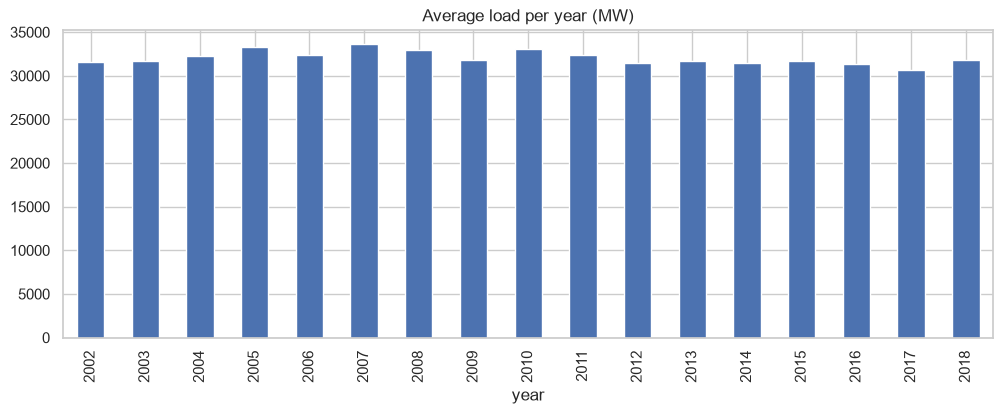

Extreme outliers: 27


In [ ]:
#Cell 7: Yearly trend and outliers
yearly = df.groupby("year")["load_mw"].mean()
yearly.plot(kind="bar", title="Average load per year (MW)")
plt.show()

q1, q3 = df["load_mw"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df["load_mw"] < q1 - 3 * iqr) | (df["load_mw"] > q3 + 3 * iqr)]
print("Extreme outliers:", len(outliers))

In [ ]:
#Cell 8: Save the cleaned data
print(outliers["load_mw"].sort_values(ascending=False).head(10))
print(outliers.index.date.tolist()[:27])

Datetime
2006-08-02 17:00:00    62009.0
2006-08-02 16:00:00    61909.0
2006-08-03 17:00:00    61796.0
2006-08-03 16:00:00    61770.0
2011-07-22 15:00:00    61646.0
2006-08-01 17:00:00    61643.0
2006-08-02 15:00:00    61641.0
2006-08-02 18:00:00    61610.0
2011-07-22 16:00:00    61608.0
2011-07-22 14:00:00    61532.0
Name: load_mw, dtype: float64
[datetime.date(2006, 7, 18), datetime.date(2006, 8, 1), datetime.date(2006, 8, 1), datetime.date(2006, 8, 1), datetime.date(2006, 8, 1), datetime.date(2006, 8, 1), datetime.date(2006, 8, 1), datetime.date(2006, 8, 2), datetime.date(2006, 8, 2), datetime.date(2006, 8, 2), datetime.date(2006, 8, 2), datetime.date(2006, 8, 2), datetime.date(2006, 8, 2), datetime.date(2006, 8, 3), datetime.date(2006, 8, 3), datetime.date(2006, 8, 3), datetime.date(2006, 8, 3), datetime.date(2006, 8, 3), datetime.date(2011, 7, 21), datetime.date(2011, 7, 21), datetime.date(2011, 7, 21), datetime.date(2011, 7, 22), datetime.date(2011, 7, 22), datetime.date(2011, 7, 

In [8]:
df.to_csv("../data/processed/pjme_clean.csv")